# 1. Import thư viện
## Sử dụng các thư viện:
- streamlit: xây dựng giao diện người dùng cho hệ thống.
- pandas, numpy: đọc, xử lý và tạo dữ liệu đầu vào cho các mô hình.
- joblib: tải các mô hình và scaler đã được huấn luyện từ các file .pkl.
- matplotlib: hỗ trợ vẽ biểu đồ trực quan hóa kết quả.
- StandardScaler: không cần import trực tiếp, vì Task 5 sử dụng scaler đã được lưu từ quá trình huấn luyện của Dương và Hải.


In [1]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import  os

reg_model = joblib.load("regression_model.pkl")
reg_scaler = joblib.load("regression_scaler.pkl")
cls_model = joblib.load("classification_model.pkl")
cls_scaler = joblib.load("classification_scaler.pkl")
clustered_data = pd.read_csv("clustered_data.csv")

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle 

In [2]:


reg_model = joblib.load("regression_model.pkl")
reg_scaler = joblib.load("regression_scaler.pkl")

cls_model = joblib.load("classification_model.pkl")
cls_scaler = joblib.load("classification_scaler.pkl")

print("Load Regression thành công")
print("Load Classification thành công")

Load Regression thành công
Load Classification thành công


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle 

# 2.Kiểm tra dữ liệu và model

In [3]:
files = [
    "cleaned_data.csv",
    "clustered_data.csv",
    "regression_model.pkl",
    "regression_scaler.pkl",
    "classification_model.pkl",
    "classification_scaler.pkl"
]

print("KIỂM TRA CÁC FILE")
print("-" * 40)

for file in files:
    if os.path.exists(file):
        print(f"{file}: Tồn tại")
    else:
        print(f"{file}: Không tìm thấy")

KIỂM TRA CÁC FILE
----------------------------------------
cleaned_data.csv: Tồn tại
clustered_data.csv: Tồn tại
regression_model.pkl: Tồn tại
regression_scaler.pkl: Tồn tại
classification_model.pkl: Tồn tại
classification_scaler.pkl: Tồn tại


# 3.Load dữ liệu
Đọc hai file dữ liệu:

- `cleaned_data.csv`: dữ liệu đã được làm sạch.
- `clustered_data.csv`: dữ liệu đã được gán nhãn Cluster.

`clustered_data.csv` được sử dụng để hiển thị và trực quan hóa
kết quả phân cụm K-Means.

In [4]:
cleaned_data = pd.read_csv("cleaned_data.csv")
clustered_data = pd.read_csv("clustered_data.csv")

print("Kích thước cleaned_data:", cleaned_data.shape)
print("Kích thước clustered_data:", clustered_data.shape)

display(cleaned_data.head())

Kích thước cleaned_data: (689, 21)
Kích thước clustered_data: (689, 22)


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05


# 4.Load mô hình Regression

Load:

- `regression_model.pkl`: mô hình dùng để dự đoán giá.
- `regression_scaler.pkl`: scaler được sử dụng trong quá trình huấn luyện.

Dữ liệu đầu vào của người dùng phải được đưa qua scaler
trước khi đưa vào Regression model.

Quy trình:

Input → Regression Scaler → Regression Model → Giá dự đoán

In [5]:
regression_model = joblib.load("regression_model.pkl")
regression_scaler = joblib.load("regression_scaler.pkl")
print("Đã load Regression model")
print("Đã load Regression scaler")

Đã load Regression model
Đã load Regression scaler


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 5.Load mô hình Classification

Load:

- `classification_model.pkl`: mô hình phân loại mức giá.
- `classification_scaler.pkl`: scaler dùng để chuẩn hóa dữ liệu đầu vào.

Dữ liệu người dùng được chuẩn hóa trước khi đưa vào Classification model.

Quy trình:

Input → Classification Scaler → Classification Model → Nhóm giá

In [6]:
classification_model = joblib.load("classification_model.pkl")
classification_scaler = joblib.load("classification_scaler.pkl")
print("Đã load Classification model")
print("Đã load Classification scaler")

Đã load Classification model
Đã load Classification scaler


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 6. Xác định các biến đầu vào

Regression và Classification sử dụng 10 biến đầu vào:

1. `screen_size`
2. `ram`
3. `rom`
4. `release_year`
5. `rating`
6. `num_reviews`
7. `monthly_views`
8. `monthly_orders`
9. `customer_rating`
10. `stock_quantity`

Các biến được giữ đúng thứ tự để đảm bảo dữ liệu đầu vào
phù hợp với quá trình huấn luyện model.

In [7]:
FEATURES = [
    "screen_size",
    "ram",
    "rom",
    "release_year",
    "rating",
    "num_reviews",
    "monthly_views",
    "monthly_orders",
    "customer_rating",
    "stock_quantity"
]
print("Số lượng features:", len(FEATURES))
print("Features sử dụng:")
print(FEATURES)

Số lượng features: 10
Features sử dụng:
['screen_size', 'ram', 'rom', 'release_year', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']


## 7. Tạo dữ liệu đầu vào từ người dùng

Trước khi xây dựng Streamlit UI, tạo một bộ dữ liệu mẫu
đại diện cho thông tin mà người dùng sẽ nhập trên giao diện.

Bộ dữ liệu này được sử dụng để kiểm tra trực tiếp khả năng
chạy của Regression và Classification model.

In [8]:
input_data = pd.DataFrame([{
    "screen_size": 6.5,
    "ram": 8,
    "rom": 128,
    "release_year": 2024,
    "rating": 4.5,
    "num_reviews": 100,
    "monthly_views": 1000,
    "monthly_orders": 100,
    "customer_rating": 4.5,
    "stock_quantity": 100
}])

display(input_data)

,screen_size,ram,rom,release_year,rating,num_reviews,monthly_views,monthly_orders,customer_rating,stock_quantity
0,6.5,8,128,2024,4.5,100,1000,100,4.5,100


## 8. Tích hợp Regression

Thực hiện dự đoán giá sản phẩm.

Các bước:

1. Nhận dữ liệu đầu vào.
2. Chuẩn hóa dữ liệu bằng `regression_scaler`.
3. Đưa dữ liệu đã chuẩn hóa vào `regression_model`.
4. Nhận giá dự đoán.

Đây là bước kiểm tra model có thể chạy với dữ liệu người dùng
trước khi đưa vào giao diện Streamlit.

In [9]:
# Bước này là bước chuẩn hóa dữ liểu và dự đoán giá
input_scaled_regression = regression_scaler.transform(input_data)
regression_prediction = regression_model.predict(input_scaled_regression)[0]

print(f"Giá sản phẩm dự đoán: {regression_prediction:,.0f}")

Giá sản phẩm dự đoán: 16,690,000


## 9. Tích hợp Classification

Thực hiện phân loại sản phẩm theo nhóm giá.

Các bước:

1. Nhận dữ liệu đầu vào.
2. Chuẩn hóa dữ liệu bằng `classification_scaler`.
3. Đưa dữ liệu đã chuẩn hóa vào `classification_model`.
4. Nhận nhóm giá dự đoán.

In [10]:
input_scaled_classification = classification_scaler.transform(input_data)
classification_prediction = classification_model.predict(input_scaled_classification)[0]
print(f"Nhóm giá dự đoán: {classification_prediction}")

Nhóm giá dự đoán: High


## 10. Tích hợp kết quả K-Means

Kết quả K-Means được lấy từ `clustered_data.csv`.

Kiểm tra cột `Cluster_Label` để xác nhận dữ liệu đã có kết quả
phân cụm.

Trong Task 5, K-Means được sử dụng để hiển thị và trực quan hóa
kết quả phân cụm đã có.

Không huấn luyện lại K-Means khi người dùng thực hiện dự đoán.

In [11]:
print("Các cột của clustered_data:")
print(clustered_data.columns.tolist())

if "Cluster_Label" in clustered_data.columns:
    print("\nĐã tìm thấy Cluster_Label")
else:
    print("\nKhông tìm thấy Cluster_Label")

Các cột của clustered_data:
['product_name', 'price', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications', 'source', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity', 'data_date', 'Cluster_Label']

Đã tìm thấy Cluster_Label


## 11. Visualization – Phân bố Cluster

Đếm số lượng sản phẩm thuộc từng Cluster.

Biểu đồ giúp người dùng quan sát sự phân bố của các nhóm
sản phẩm sau khi thực hiện K-Means.

In [12]:
cluster_counts = (
    clustered_data["Cluster_Label"]
    .value_counts()
    .sort_index()
)
print("Số lượng sản phẩm theo Cluster:")
display(cluster_counts)
plt.figure(figsize=(8, 5))
plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values)
plt.xlabel("Cluster")
plt.ylabel("Số lượng sản phẩm")
plt.title("Phân bố sản phẩm theo Cluster")
plt.show()

Số lượng sản phẩm theo Cluster:


Cluster_Label
0    688
1      1
Name: count, dtype: int64

C:\Users\Admin\AppData\Local\Temp\ipykernel_2836\3767312648.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 12. Visualization – Scatter Plot theo Cluster

Sử dụng hai biến số để trực quan hóa sự phân bố sản phẩm
theo từng Cluster.

Mỗi Cluster được hiển thị với một nhóm điểm riêng,
giúp quan sát sự phân tách giữa các nhóm dữ liệu.

In [13]:
numeric_cols = (
    clustered_data
    .select_dtypes(include="number")
    .columns
    .tolist()
)

numeric_cols = [
    col for col in numeric_cols
    if col != "Cluster_Label"
]

print("Các biến số có thể dùng để trực quan hóa:")
print(numeric_cols)

Các biến số có thể dùng để trực quan hóa:
['price', 'release_year', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']


In [14]:
x_col = numeric_cols[0]
y_col = numeric_cols[1]

plt.figure(figsize=(9, 5))

for label, group in clustered_data.groupby(
    "Cluster_Label"
):
    plt.scatter(
        group[x_col],
        group[y_col],
        label=f"Cluster {label}",
        alpha=0.6
    )

plt.xlabel(x_col)
plt.ylabel(y_col)

plt.title(
    f"{x_col} và {y_col} theo Cluster"
)

plt.legend()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_2836\899021811.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 13. Xây dựng giao diện người dùng bằng Streamlit

Giao diện cho phép người dùng nhập 10 thông tin sản phẩm:

- Kích thước màn hình
- RAM
- ROM
- Năm phát hành
- Rating
- Số lượt đánh giá
- Lượt xem hàng tháng
- Đơn hàng hàng tháng
- Đánh giá khách hàng
- Số lượng tồn kho

Sau khi nhập dữ liệu, người dùng có thể:

- Dự đoán giá bằng Regression.
- Phân loại mức giá bằng Classification.
- Xem kết quả phân cụm K-Means.

In [15]:
app_code = r'''

reg_model = joblib.load("regression_model.pkl")
reg_scaler = joblib.load("regression_scaler.pkl")
cls_model = joblib.load("classification_model.pkl")
cls_scaler = joblib.load("classification_scaler.pkl")
clustered_data = pd.read_csv("clustered_data.csv")

st.title("📱 HỆ THỐNG DỰ ĐOÁN SẢN PHẨM")

# Nhập dữ liệu
st.header("📝 Nhập thông tin")

values = [
    st.number_input("Kích thước màn hình", value=6.5),
    st.number_input("RAM (GB)", value=8.0),
    st.number_input("ROM (GB)", value=128.0),
    st.number_input("Năm phát hành", value=2024),
    st.number_input("Rating", 0.0, 5.0, 4.5),
    st.number_input("Số lượt đánh giá", value=100),
    st.number_input("Lượt xem/tháng", value=1000),
    st.number_input("Đơn hàng/tháng", value=100),
    st.number_input("Đánh giá khách hàng", 0.0, 5.0, 4.5),
    st.number_input("Tồn kho", value=100)
]

features = [
    "screen_size", "ram", "rom", "release_year", "rating",
    "num_reviews", "monthly_views", "monthly_orders",
    "customer_rating", "stock_quantity"
]

input_data = pd.DataFrame([values], columns=features)

# Regression
if st.button("Dự đoán giá"):
    x = reg_scaler.transform(input_data)
    result = reg_model.predict(x)[0]
    st.success(f"Giá dự đoán: {result:,.0f}")

# Classification
if st.button("Phân loại giá"):
    x = cls_scaler.transform(input_data)
    result = cls_model.predict(x)[0]
    st.success(f"Nhóm giá: {result}")

# K-Means
st.header("K-Means")

if "Cluster_Label" in clustered_data.columns:
    counts = clustered_data["Cluster_Label"].value_counts().sort_index()
    st.bar_chart(counts)

    st.dataframe(clustered_data.head(20))
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("Đã tạo app.py")

Đã tạo app.py


In [16]:
from pathlib import Path
app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
reg_model = joblib.load("regression_model.pkl")
reg_scaler = joblib.load("regression_scaler.pkl")
cls_model = joblib.load("classification_model.pkl")
cls_scaler = joblib.load("classification_scaler.pkl")
clustered_data = pd.read_csv("clustered_data.csv")

st.title("HỆ THỐNG DỰ ĐOÁN SẢN PHẨM")

st.header("Nhập thông tin")

values = [
    st.number_input("Kích thước màn hình", value=6.5),
    st.number_input("RAM (GB)", value=8.0),
    st.number_input("ROM (GB)", value=128.0),
    st.number_input("Năm phát hành", value=2024),
    st.number_input("Rating", 0.0, 5.0, 4.5),
    st.number_input("Số lượt đánh giá", value=100),
    st.number_input("Lượt xem/tháng", value=1000),
    st.number_input("Đơn hàng/tháng", value=100),
    st.number_input("Đánh giá khách hàng", 0.0, 5.0, 4.5),
    st.number_input("Tồn kho", value=100)
]

features = [
    "screen_size", "ram", "rom", "release_year", "rating",
    "num_reviews", "monthly_views", "monthly_orders",
    "customer_rating", "stock_quantity"
]

input_data = pd.DataFrame([values], columns=features)

if st.button("Dự đoán giá"):
    x = reg_scaler.transform(input_data)
    result = reg_model.predict(x)[0]
    st.success(f"Giá dự đoán: {result:,.0f}")

if st.button("Phân loại giá"):  
    x = cls_scaler.transform(input_data)
    result = cls_model.predict(x)[0]
    st.success(f"Nhóm giá: {result}")

st.header("K-Means")

if "Cluster_Label" in clustered_data.columns:
    counts = clustered_data["Cluster_Label"].value_counts().sort_index()
    st.bar_chart(counts)
    st.dataframe(clustered_data.head(20))
'''

app_path = Path.cwd() / "app.py"

with open(app_path, "w", encoding="utf-8") as f:
    f.write(app_code)

print("Đã ghi app.py tại:", app_path)

Đã ghi app.py tại: d:\Task 5_Tài (1)\app.py


# 14. Kết quả chạy giao diện

Giao diện Streamlit đã được chạy thành công và kiểm thử với dữ liệu mẫu.

Các ảnh dưới đây minh họa:
- Giao diện nhập thông tin sản phẩm.
- Kết quả dự đoán từ hệ thống.
- Giao diện và kết quả trực quan hóa K-Means.
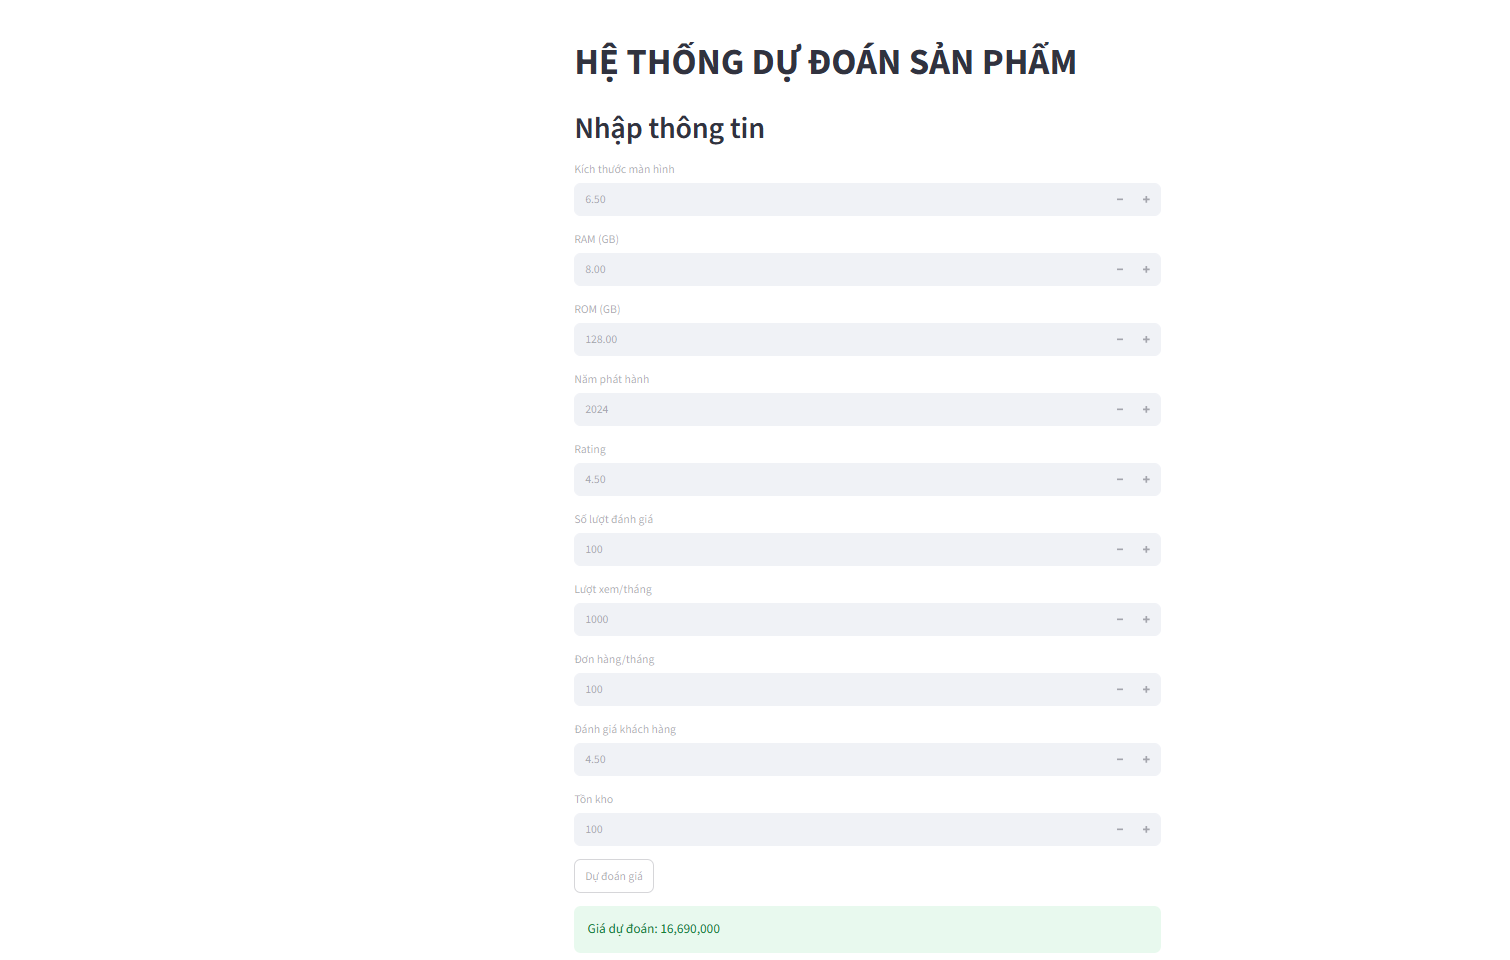

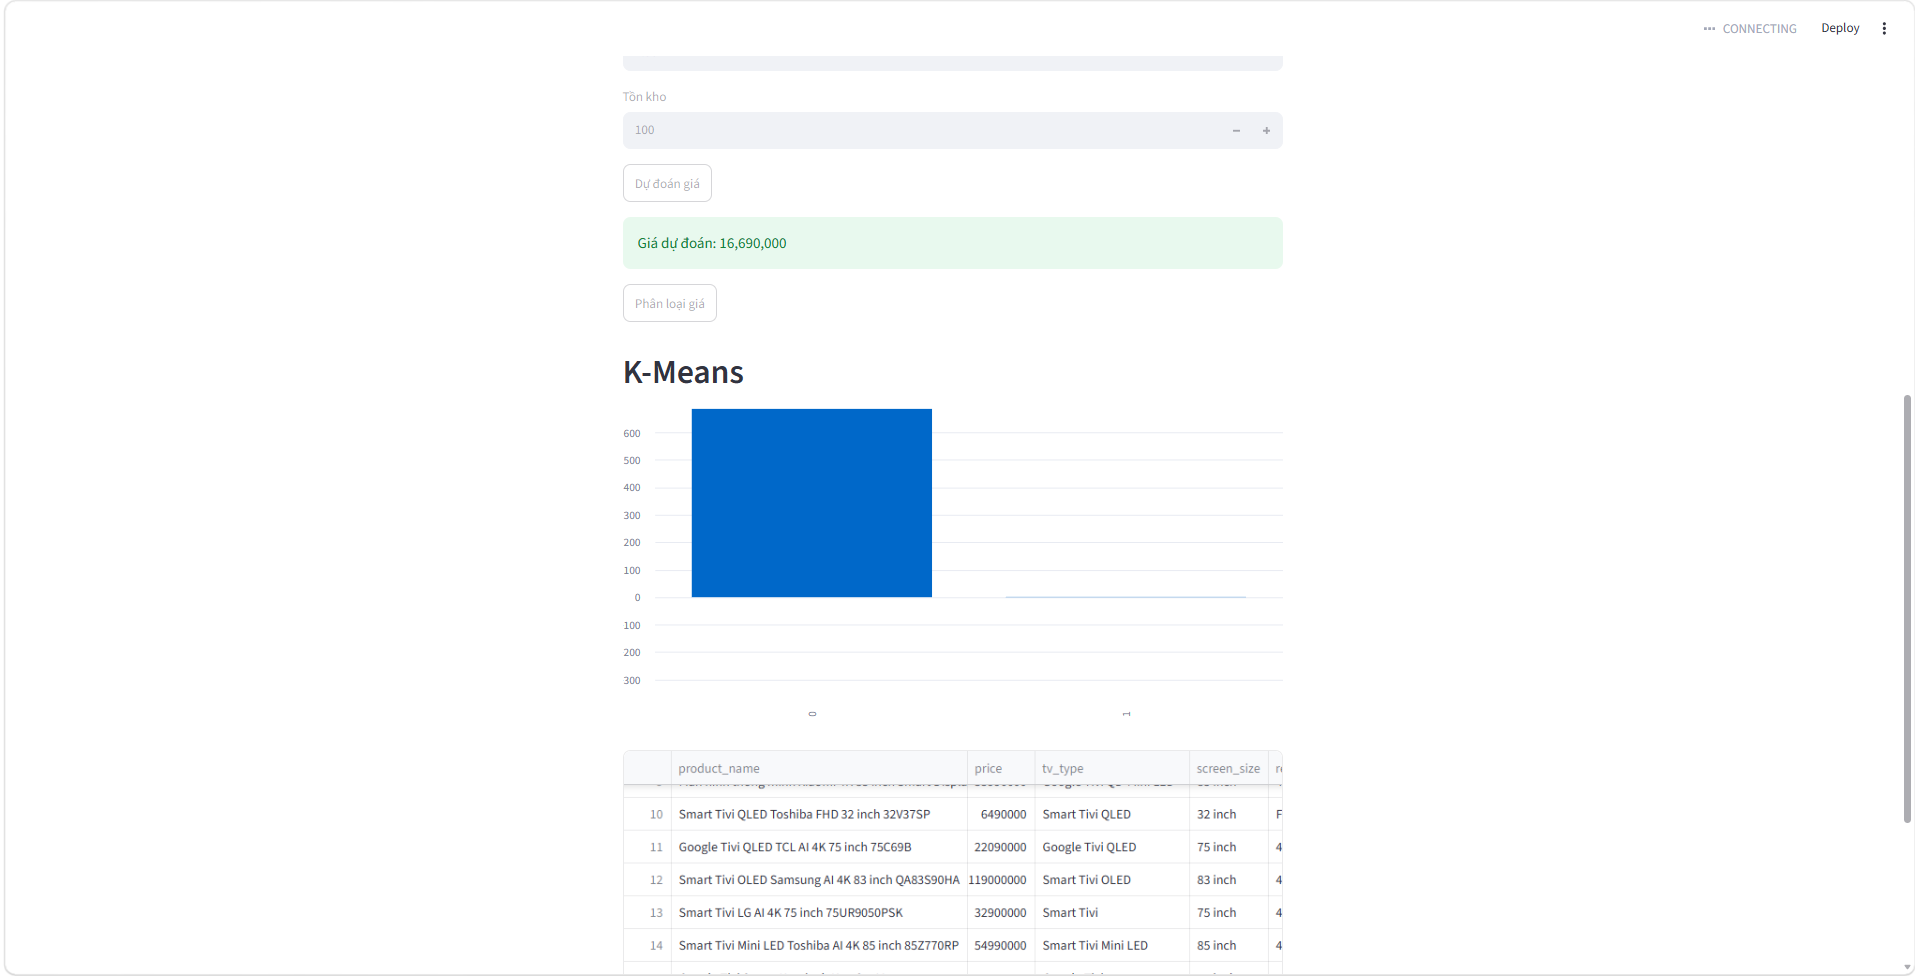

# 14. Hướng dẫn chạy Streamlit

Giao diện Streamlit được xây dựng trong file `app.py`.

Để khởi động giao diện trực tiếp từ Jupyter Notebook, chạy ô code bên dưới.

Sau khi chạy, hệ thống sẽ tự động khởi động Streamlit và mở giao diện trên trình duyệt tại:

`http://localhost:8501`

Giao diện cho phép người dùng:
- Nhập thông tin sản phẩm.
- Dự đoán giá bằng mô hình Regression.
- Phân loại nhóm giá bằng mô hình Classification.
- Xem kết quả phân cụm K-Means từ `clustered_data.csv`.

**Lưu ý:** Các file `app.py`, model `.pkl` và dữ liệu `.csv` cần nằm trong cùng thư mục làm việc.

In [17]:
import subprocess
import webbrowser
import time
from pathlib import Path

app_path = Path.cwd() / "app.py"

process = subprocess.Popen(
    ["py", "-m", "streamlit", "run", str(app_path)],
    cwd=str(app_path.parent)
)

time.sleep(3)

webbrowser.open("http://localhost:8501")

print("Streamlit đang chạy tại:")
print("http://localhost:8501")

Streamlit đang chạy tại:
http://localhost:8501


# KẾT LUẬN

Task 5 đã hoàn thành việc tích hợp các mô hình Machine Learning vào giao diện người dùng bằng Streamlit.

Hệ thống cho phép người dùng nhập các thông tin của sản phẩm và thực hiện:
- Dự đoán giá sản phẩm bằng mô hình Regression.
- Phân loại sản phẩm theo nhóm giá bằng mô hình Classification.
- Hiển thị kết quả phân cụm K-Means và trực quan hóa dữ liệu.

Các mô hình và scaler được load trực tiếp từ các file `.pkl` đã được huấn luyện trước đó. 
Dữ liệu đầu vào được đưa qua scaler tương ứng trước khi thực hiện dự đoán, đảm bảo quá trình xử lý trên UI phù hợp với mô hình đã huấn luyện.

Hệ thống không huấn luyện lại mô hình khi người dùng thực hiện dự đoán, giúp giao diện hoạt động nhanh và đúng yêu cầu của Task 5.

Qua quá trình kiểm thử, giao diện Streamlit có thể nhận dữ liệu từ người dùng và hiển thị kết quả dự đoán trực tiếp trên giao diện.